# ChestScan AI - Partie 1 : donnees  /  Partie 2 : modele CNN

> **Prototype pedagogique. Ce modele n'est pas destine au diagnostic medical.**

## Avant de commencer (Colab)

1. **Activez le GPU** : menu *Execution > Modifier le type d'execution > GPU > T4* puis enregistrer.
   Sans GPU le notebook fonctionne quand meme ici (aucun entrainement), mais sera plus lent partout ailleurs.
2. Puis faites *Execution > Tout executer* (le notebook tourne de bout en bout, sans rien modifier).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/VOTRE_USER/VOTRE_REPO/blob/main/notebook-simple.ipynb)

*(Remplacez `VOTRE_USER` et `VOTRE_REPO` par vos identifiants GitHub.)*

## Ce que contient ce notebook

| Partie | Contenu |
|--------|---------|
| **1. Donnees** | importer, explorer les dossiers, compter, charger les images en 180x180 RGB, gerer les images cassees, split train/validation/test, normalisation, visualisation, desequilibre + `class_weight` |
| **2. Modele** | principe d'un CNN, architecture `Sequential` couche par couche, `compile`, `model.summary()` |

**Ce que ce notebook ne fait PAS** (volontairement) : `model.fit()`, courbes, evaluation sur le test, sauvegarde, `predict_xray`, application Streamlit. Ces etapes sont dans les autres fichiers du projet (`notebook.ipynb`, `app.py`).

### Etape 1 : installer ce qui manque

**Ce qu'on fait** : on installe `kagglehub` (le script qui telecharge le dataset Kaggle).

**Pourquoi** : Colab fournit deja TensorFlow, NumPy, scikit-learn, Matplotlib, seaborn et Pillow.
Seul `kagglehub` manque parfois. On ne re-installe donc JAMAIS ce qui est deja la :
re-installer tout serait long et peut casser l'environnement de Colab.

In [1]:
# -q = silencieux : on n affiche que les erreurs
# On n installe QUE ce qui manque, jamais TensorFlow/numpy/scikit-learn (deja presents dans Colab)
!pip install -q kagglehub

### Etape 2 : importer les bibliotheques et definir les regles du jeu

**Ce qu'on fait** : on importe ce dont on a besoin, puis on declare **en haut** toutes les
variables de reglage (`SEED`, `IMG_SIZE`, `BATCH_SIZE`, `EPOCHS`, `LEARNING_RATE`).

**Pourquoi** : c'est comme les regles d'un jeu annoncees avant de commencer. Tout est au meme
endroit : pour changer la taille des images ou le pas d'apprentissage, on ne cherche pas dans
le notebook, on modifie une seule ligne. La `SEED` rend les resultats repetables : sans elle,
chaque execution redecoupe les donnees autrement et les chiffres changent.

In [2]:
import json
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import (
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    Input,
    MaxPooling2D,
    RandomFlip,
    RandomRotation,
    RandomZoom,
)
from tensorflow.keras.metrics import AUC, Precision, Recall
from tensorflow.keras.models import Sequential

# ---- Reglages du projet (tout est ICI, en haut) ----
SEED = 42             # graine aleatoire : pour des resultats repetables d une execution a l autre
IMG_SIZE = 180        # taille des carrees des images (imposee par le sujet : 180x180)
BATCH_SIZE = 32       # nombre d images envoyees ensemble a chaque pas (ne sert que plus tard)
EPOCHS = 20           # nombre maximum d epochs (ne sert que plus tard, pas d entrainement ici)
LEARNING_RATE = 0.001 # pas d apprentissage de l optimiseur Adam (idem, pour plus tard)

# On fixe la graine partout : TensorFlow, NumPy et Python
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


### Etape 3 : verifier qu'un GPU est bien visible

**Ce qu'on fait** : on demande a TensorFlow s'il voit un GPU.

**Pourquoi** : sur Colab, le GPU n'est pas actif par defaut. Un message clair ici evite de se
rendre compte 30 minutes plus tard que tout tourne 10 fois trop lentement.

In [3]:
gpu = tf.config.list_physical_devices("GPU")
if gpu:
    print("GPU utilise :", gpu)
else:
    print("Aucun GPU visible.")
    print("Sur Colab : menu Execution > Modifier le type d execution > GPU (T4) puis re-executer.")
    print("Ici le notebook fonctionne quand meme : il n y a pas d entrainement dans ce notebook.")

Aucun GPU visible.
Sur Colab : menu Execution > Modifier le type d execution > GPU (T4) puis re-executer.
Ici le notebook fonctionne quand meme : il n y a pas d entrainement dans ce notebook.


# Partie 1 - Chargement et pretraitement du dataset

### Etape 4 : d'ou viennent les donnees ?

**Ce qu'on fait** : on choisit la source des images avec la variable `SOURCE_DONNEES` :

- `"kaggle"` (par defaut) : telechargement automatique avec `kagglehub` ;
- `"drive"` : lecture depuis Google Drive (a adapter dans le code) ;
- `"local"` : le dossier `data/chest_xray` est deja sur le disque, rien n est telecharge.

**Pourquoi** : ce notebook doit marcher a l identique chez moi, chez toi et sur Colab.
Un seul choix en haut, aucun chemin fige en dur.

**Attention Kaggle** : le dataset n'est pas telechargeable anonymement. Si une authentification
est demandee, il faut :
1. creer un token sur [kaggle.com](https://www.kaggle.com) > profil > *Settings > Create API Token*
   (cela televerse un fichier `kaggle.json`) ;
2. en Colab : *Session > Fichiers* et televerser `kaggle.json` dans `/root/.kaggle/`
   — **jamais ce fichier ni ce mot de passe ne sont ecrits dans ce notebook** ;
3. ou executer `kagglehub.login()` et coller le token.

Si le chargement echoue, le message d'erreur indique exactement quoi faire.

In [4]:
# "kaggle" = telechargement auto (Colab) | "drive" = Google Drive | "local" = deja sur le disque
SOURCE_DONNEES = "kaggle"
CHEMIN_LOCAL = os.path.join("data", "chest_xray")  # chemin relatif : aucun chemin fige en dur

if SOURCE_DONNEES == "drive":
    from google.colab import drive

    drive.mount("/content/drive")
    CHEMIN_DONNEES = "/content/drive/MyDrive/chest_xray"  # A ADAPTER selon votre dossier Drive
elif os.path.exists(CHEMIN_LOCAL):
    # Le dataset est deja sur le disque : on l utilise tel quel (economise un telechargement)
    CHEMIN_DONNEES = CHEMIN_LOCAL
    print("Dataset deja present sur le disque, pas de re-telechargement.")
else:
    try:
        import kagglehub

        dossier = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
        CHEMIN_DONNEES = os.path.join(dossier, "chest_xray")
    except Exception as erreur:
        print("ERREUR : impossible de telecharger le dataset.")
        print("Cause probable : le dataset Kaggle n est pas telechargeable anonymement.")
        print("Que faire :")
        print("  1. Creer un token sur kaggle.com > profil > Settings > Create API Token.")
        print("  2. En Colab : Session > Fichiers > televerser kaggle.json dans /root/.kaggle/")
        print("  3. Ou executer kagglehub.login() et coller le token.")
        print("  4. Ou placer le dossier chest_xray dans data/ et passer SOURCE_DONNEES = 'local'.")
        raise

print("Dossier utilise :", CHEMIN_DONNEES)
print("Contenu :", sorted(os.listdir(CHEMIN_DONNEES)))

Dataset deja present sur le disque, pas de re-telechargement.
Dossier utilise : data\chest_xray
Contenu : ['.DS_Store', 'test', 'train', 'val']


### Etape 5 : explorer la structure des dossiers

**Ce qu'on fait** : on regarde l'arborescence : 3 dossiers (`train`, `val`, `test`), et dans
chacun 2 sous-dossiers = nos 2 classes : `NORMAL` et `PNEUMONIA`.

**Pourquoi** : c'est la base de ce type de dataset. Les labels ne sont pas dans un fichier :
ils sont **dans les noms des dossiers**. NORMAL = 0, PNEUMONIA = 1. Si on se trompe ici,
tout le reste est fausse.

In [5]:
SPLITS = ["train", "val", "test"]   # les 3 dossiers d origine du dataset
CLASSES = ["NORMAL", "PNEUMONIA"]  # index 0 = NORMAL, index 1 = PNEUMONIA (label = nom du dossier)
EXTENSIONS_IMAGE = (".jpeg", ".jpg", ".png", ".bmp")

for dossier in SPLITS:
    chemin = os.path.join(CHEMIN_DONNEES, dossier)
    print(f"{dossier}/ -> sous-dossiers : {sorted(os.listdir(chemin))}")
print()
print("Classes retenues :", CLASSES, "=> labels 0 et 1")

train/ -> sous-dossiers : ['.DS_Store', 'NORMAL', 'PNEUMONIA']
val/ -> sous-dossiers : ['.DS_Store', 'NORMAL', 'PNEUMONIA']
test/ -> sous-dossiers : ['.DS_Store', 'NORMAL', 'PNEUMONIA']

Classes retenues : ['NORMAL', 'PNEUMONIA'] => labels 0 et 1


### Etape 6 et 7 : compter les images par classe, en pourcentage

**Ce qu'on fait** : on compte les fichiers image de chaque dossier, on affiche un petit tableau,
puis les pourcentages.

**Pourquoi** : la toute premiere question a poser a un dataset. Le tableau revele tout de suite
le **desequilibre** : il y a bien plus de PNEUMONIA que de NORMAL. C'est ce desequilibre qui
n'obligera a prendre des precautions plus tard (`class_weight`).

In [6]:
comptage = []
for dossier in SPLITS:
    for classe in CLASSES:
        chemin = os.path.join(CHEMIN_DONNEES, dossier, classe)
        fichiers = [f for f in os.listdir(chemin) if f.lower().endswith(EXTENSIONS_IMAGE)]
        comptage.append({"dossier": dossier, "classe": classe, "images": len(fichiers)})

df_comptage = pd.DataFrame(comptage)
tableau = df_comptage.pivot(index="dossier", columns="classe", values="images")
tableau["TOTAL"] = tableau.sum(axis=1)
print(tableau)
print("Total images sur le disque :", int(df_comptage["images"].sum()))

classe   NORMAL  PNEUMONIA  TOTAL
dossier                          
test        234        390    624
train      1341       3875   5216
val           8          8     16
Total images sur le disque : 5856


In [7]:
# Repartition en pourcentages : le desequilibre se voit immediatement
total_normal = int(tableau["NORMAL"].sum())
total_pneumo = int(tableau["PNEUMONIA"].sum())
total_total = total_normal + total_pneumo

print(f"Ensemble complet : {total_normal} NORMAL  ({100 * total_normal / total_total:.1f} %)")
print(f"                  {total_pneumo} PNEUMONIA ({100 * total_pneumo / total_total:.1f} %)")
print(f"Ratio PNEUMONIA / NORMAL = {total_pneumo / total_normal:.2f}")

Ensemble complet : 1583 NORMAL  (27.0 %)
                  4273 PNEUMONIA (73.0 %)
Ratio PNEUMONIA / NORMAL = 2.70


### Etape 8 a 11 : charger les images (180x180, RGB, labels, images cassees)

**Ce qu'on fait** : une fonction courte `charger_images_dossier` + une boucle sur les 6 dossiers.
Pour chaque fichier : on l'ouvre avec Pillow, on le convertit en RGB (3 canaux), on le
redimensionne en **180 x 180**, et on le met dans un tableau NumPy **en `uint8`** (entiers de
0 a 255). Un fichier casse leve une erreur, attrapee par `try/except` : il est compté, listé, et ignoré.

**Pourquoi** :
- **`uint8`** = 1 octet par pixel au lieu de 4 : 3 fois moins de memoire pendant tout le
  chargement. On ne convertira en `float32` qu'apres le split, une seule fois.
- **`try/except`** : un seul fichier corrompu ne doit pas faire planter les 5 000 autres.
- **`.DS_Store` et autres fichiers non image** sont ignores via la liste d'extensions.

In [8]:
def charger_images_dossier(chemin_dossier, label):
    # Ouvre chaque image une par une : RGB, 180x180, en uint8 (0 a 255, pas encore normalise).
    # Retourne les images, leurs labels, et la liste des fichiers illisibles (rejetes).
    images, labels, illisibles = [], [], []
    for fichier in sorted(os.listdir(chemin_dossier)):
        if not fichier.lower().endswith(EXTENSIONS_IMAGE):
            continue  # on ignore .DS_Store et autres fichiers qui ne sont pas des images
        try:
            img = Image.open(os.path.join(chemin_dossier, fichier)).convert("RGB")
            img = img.resize((IMG_SIZE, IMG_SIZE))
            images.append(np.array(img, dtype=np.uint8))
            labels.append(label)
        except Exception:
            illisibles.append(fichier)  # image cassee : on la note, on ne s arrete pas
    return images, labels, illisibles

In [9]:
# Boucle principale : 3 dossiers x 2 classes, labels pris dans le NOM du dossier
x_images = []        # les pixels, en uint8 (0 a 255) pour economiser la memoire
y_labels = []        # les labels : 0 = NORMAL, 1 = PNEUMONIA
fichiers_ignores = []  # tout ce qui n a pas pu etre charge (illisible ou non image)

for dossier in SPLITS:
    for classe in CLASSES:
        label = CLASSES.index(classe)  # le label vient du nom du sous-dossier
        images, labels, illisibles = charger_images_dossier(
            os.path.join(CHEMIN_DONNEES, dossier, classe), label
        )
        x_images.extend(images)
        y_labels.extend(labels)
        fichiers_ignores.extend(f"{dossier}/{classe}/{f}" for f in illisibles)

x_images = np.array(x_images, dtype=np.uint8)
y_labels = np.array(y_labels, dtype=np.uint8)

print("Images chargees :", len(x_images))
print("Forme du tableau images :", x_images.shape, "-> (nb_images, hauteur, largeur, RGB)")
print("Memoire des images (uint8) :", round(x_images.nbytes / 1024**2), "Mo")
print("Images illisibles / ignores :", len(fichiers_ignores))
for fichier in fichiers_ignores:
    print("  -", fichier)

Images chargees : 5856
Forme du tableau images : (5856, 180, 180, 3) -> (nb_images, hauteur, largeur, RGB)
Memoire des images (uint8) : 543 Mo
Images illisibles / ignores : 0


**A retenir pour l'oral** : « Le label vient du **nom du dossier**, et non d'un fichier
d'annotation. Chaque image est ouverte avec Pillow, convertie en RGB puis redimensionnée en
180 x 180. Un fichier illisibles est simplement ignoré et listé, il ne fait pas crasher le
chargement. »

### Etape 12 : diviser en train / validation / test (sans fuite de donnees)

**Ce qu'on fait** : on regroupe d'abord toutes les images (le dossier `val` d'origine ne
contient que 16 images : inutilisable), puis on decoupe en 3 avec **deux appels** a
`train_test_split`, avec `stratify` et `random_state = SEED` :

1. d'abord on reserve **15 % du total pour le test** ;
2. ensuite on reserve **encore 15 % du total pour la validation** ;
3. le reste (70 %) est le **train**, la seule image que le modele verra pour apprendre.

**Pourquoi** :
- **Le test est mis de cote des le debut**, avant meme la normalisation. S'il servait a
  choisir quoi que ce soit, ce serait corriger la copie avec la correction sous les yeux :
  c'est la **fuite de donnees** (data leakage).
- **La validation** servira plus tard a surveiller l'entrainement (jamais a juger le modele).
- **`stratify`** garde la meme proportion de classes dans chaque morceau.
- **`random_state = SEED`** : le meme decoupage a chaque execution.

In [10]:
# Un petit tableau de reference : une ligne par image, avec sa classe
df_images = pd.DataFrame({"classe": [CLASSES[int(l)] for l in y_labels]})

# On calcule les tailles SUR LE TOTAL : 15 % pour le test, 15 % pour la validation
n_test = round(0.15 * len(df_images))
n_val = round(0.15 * len(df_images))
print(f"Total {len(df_images)} images -> test {n_test}, validation {n_val}, train le reste")

# Etape 1 : on reserve le test (independant, jamais utilise pour decider)
df_hors_test, df_test = train_test_split(
    df_images, test_size=n_test, stratify=df_images["classe"], random_state=SEED
)
# Etape 2 : dans le reste, on reserve la validation
df_train, df_val = train_test_split(
    df_hors_test, test_size=n_val, stratify=df_hors_test["classe"], random_state=SEED
)

# train_test_split conserve l index d origine : on l utilise pour recuperer les BONS pixels
x_train, y_train = x_images[df_train.index.to_numpy()], y_labels[df_train.index.to_numpy()]
x_val, y_val = x_images[df_val.index.to_numpy()], y_labels[df_val.index.to_numpy()]
x_test, y_test = x_images[df_test.index.to_numpy()], y_labels[df_test.index.to_numpy()]

print(f"Train      : {len(x_train)} images")
print(f"Validation : {len(x_val)} images")
print(f"Test       : {len(x_test)} images  <- independant, mis de cote pour la fin")

# On verifie que la proportion de classes est preservee dans chaque sous-ensemble
for nom, y_partie in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    part_normal = 100.0 * (y_partie == 0).mean()
    print(f"{nom:11s} => NORMAL {part_normal:5.1f} % | PNEUMONIA {100 - part_normal:5.1f} %")

Total 5856 images -> test 878, validation 878, train le reste


Train      : 4100 images
Validation : 878 images
Test       : 878 images  <- independant, mis de cote pour la fin
train       => NORMAL  27.0 % | PNEUMONIA  73.0 %
validation  => NORMAL  27.0 % | PNEUMONIA  73.0 %
test        => NORMAL  27.0 % | PNEUMONIA  73.0 %


**A retenir pour l'oral** : « Le test est mis de côté **dès le début**, avant toute
normalisation, et il ne sera ouvert qu'une seule fois, à la fin. La validation sert à
surveiller l'entraînement, jamais à juger le modèle. `stratify` garantit la même proportion
de classes dans les trois sous-ensembles. »

### Etape 13 : normaliser UNE SEULE FOIS (division par 255)

**Ce qu'on fait** : apres le split, on convertit les pixels en `float32` et on divise par 255.0,
pour train, validation et test, **avec exactement la meme operation**.

**Pourquoi** :
- Les pixels vont de 0 a 255. Les reseaux de neurones apprennent mieux quand les entrees sont
  petites et comparables : on les ramene dans **[0, 1]**.
- **Une seule fois, et nulle part ailleurs** : il n'y a **PAS de couche `Rescaling`** dans le
  modele (voir partie 2). Si on divisait deux fois, les valeurs seraient fausses et le modele
  n'apprendrait rien de correct.
- Le split a ete fait **avant** cette division, pour eviter tout doute de fuite de donnees.

In [11]:
# La division par 255 est faite ICI, une seule fois, et nulle part ailleurs dans le projet.
# Le modele n a PAS de couche Rescaling : c est ce tableau normalise qui lui est donne.
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# On supprime le tableau uint8 d origine pour liberer de la memoire (il ne sert plus)
del x_images

for nom, x_partie in [("train", x_train), ("validation", x_val), ("test", x_test)]:
    print(
        f"{nom:11s} => forme {x_partie.shape}, "
        f"valeurs de {x_partie.min():.3f} a {x_partie.max():.3f}, "
        f"memoire {round(x_partie.nbytes / 1024**2)} Mo"
    )

train       => forme (4100, 180, 180, 3), valeurs de 0.000 a 1.000, memoire 1520 Mo
validation  => forme (878, 180, 180, 3), valeurs de 0.000 a 1.000, memoire 326 Mo
test        => forme (878, 180, 180, 3), valeurs de 0.000 a 1.000, memoire 326 Mo


**A retenir pour l'oral** : « La normalisation est une simple division par 255, faite **après**
le split et **une seule fois**. Elle n'existe nulle part ailleurs : pas de couche `Rescaling`
dans le modèle. C'est le seul endroit du projet où les pixels sont transformés en valeurs
entre 0 et 1. »

### Etape 14 : regarder des images de chaque classe

**Ce qu'on fait** : on affiche 5 images NORMAL et 5 images PNEUMONIA du train.

**Pourquoi** : on ne fait jamais confiance a un dataset sans l'avoir **regarde**. Si les labels
dans les dossiers ne correspondaient pas aux vraies images, tout le travail serait inutilisable.
Matplotlib sait afficher un tableau float32 dont les valeurs sont deja dans [0, 1].

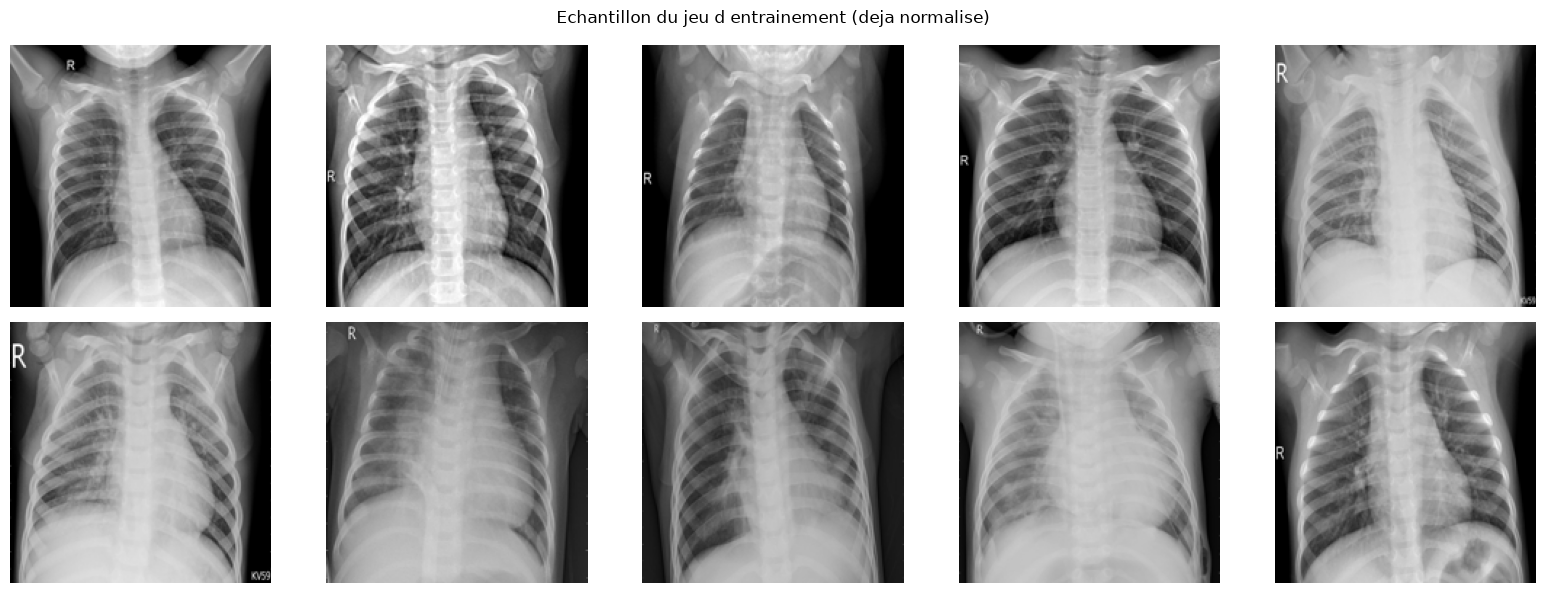

In [12]:
def afficher_exemples(images, labels, titre):
    # Montre jusqu a 5 images de chaque classe : une ligne par classe
    fig, axes = plt.subplots(2, 5, figsize=(16, 6))
    for ligne, label in enumerate([0, 1]):
        indexes = np.where(labels == label)[0][:5]
        for colonne, idx in enumerate(indexes):
            axes[ligne, colonne].imshow(images[idx])
            axes[ligne, colonne].axis("off")
        axes[ligne, 0].set_ylabel(CLASSES[label], fontsize=13)
    fig.suptitle(titre)
    plt.tight_layout()
    plt.show()


afficher_exemples(x_train, y_train, "Echantillon du jeu d entrainement (deja normalise)")

### Etape 15 : la distribution des classes, en graphique

**Ce qu'on fait** : deux graphiques. A gauche : le dataset complet par dossier d'origine.
A droite : nos 3 sous-ensembles apres le split.

**Pourquoi** : le graphique de droite prouve visuellement que `stratify` a fait son travail :
la meme proportion de classes partout. Sinon, un sous-ensemble aurait pu n'avoir que des
PNEUMONIA.

classe      PNEUMONIA  NORMAL
train            2991    1109
validation        641     237
test              641     237


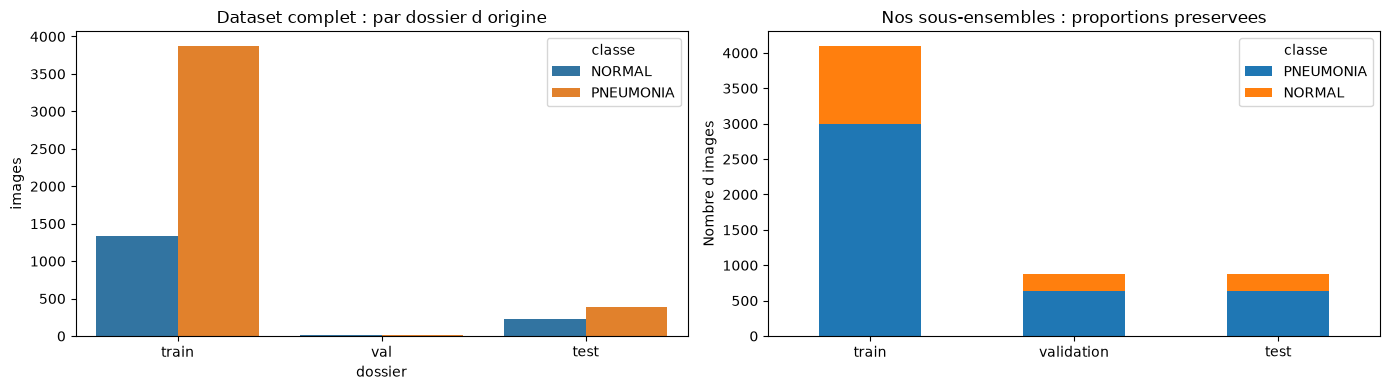

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(data=df_comptage, x="dossier", y="images", hue="classe", ax=ax[0])
ax[0].set_title("Dataset complet : par dossier d origine")

# Nombre d images par classe dans CHACUN de nos sous-ensembles (apres le split)
comptage_split = pd.DataFrame(
    {
        "train": df_train["classe"].value_counts(),
        "validation": df_val["classe"].value_counts(),
        "test": df_test["classe"].value_counts(),
    }
).T
print(comptage_split)
comptage_split.plot(kind="bar", stacked=True, rot=0, ax=ax[1])
ax[1].set_title("Nos sous-ensembles : proportions preservees")
ax[1].set_ylabel("Nombre d images")

plt.tight_layout()
plt.show()

### Etape 16 : le desequilibre et la strategie (`class_weight`)

**Ce qu'on fait** : on calcule le rapport entre les classes, on explique le risque, puis on
calcule un poids par classe avec la formule simple :

`poids = total_des_images / (2 * nombre_de_la_classe)`

**Le risque** : avec ~3 PNEUMONIA pour 1 NORMAL, un modele paresseux qui repondrait
**toujours PNEUMONIA** obtiendrait deja ~74 % de reussite... en being totalement inutile
(il n'aurait repere aucun cas normal). C'est pour cela qu'on ne regarde pas que l'accuracy.

**La strategie** : pendant l'entrainement (dans un autre notebook), chaque image NORMAL ratée
coutera plus cher qu'une image PNEUMONIA ratée. Le dictionnaire `class_weight` est **calcule
ici sur le train seulement** (sur les autres jeux, ce serait de l'information qui fuit), et
sera donne plus tard a `model.fit(class_weight=...)`.

In [14]:
# Formule simple et symetrique, calculee sur le TRAIN seulement
total_train = len(y_train)
nombre_normal = int((y_train == 0).sum())
nombre_pneumo = int((y_train == 1).sum())

poids_normal = total_train / (2 * nombre_normal)
poids_pneumo = total_train / (2 * nombre_pneumo)

class_weight = {0: poids_normal, 1: poids_pneumo}

print(f"Train : {nombre_normal} NORMAL, {nombre_pneumo} PNEUMONIA, total {total_train}")
print(f"Poids NORMAL    = {total_train} / (2 x {nombre_normal}) = {poids_normal:.3f}")
print(f"Poids PNEUMONIA = {total_train} / (2 x {nombre_pneumo}) = {poids_pneumo:.3f}")
print("Dictionnaire conserve pour model.fit(class_weight=...) lors de l entrainement :")
print(class_weight)

Train : 1109 NORMAL, 2991 PNEUMONIA, total 4100
Poids NORMAL    = 4100 / (2 x 1109) = 1.849
Poids PNEUMONIA = 4100 / (2 x 2991) = 0.685
Dictionnaire conserve pour model.fit(class_weight=...) lors de l entrainement :
{0: 1.848512173128945, 1: 0.6853895018388498}


**A retenir pour l'oral** : « Le jeu de données est déséquilibré : environ 3 PNEUMONIA pour
1 NORMAL. Un modèle qui prédit toujours PNEUMONIA atteindrait ~74 % d'accuracy en étant
inutile. Je corrige cela avec `class_weight`, calculé sur le train avec la formule
`total / (2 x nombre_de_la_classe)`, qui pénalise davantage les erreurs sur la classe rare. »

# Partie 2 - Conception du modele CNN

### Pourquoi un CNN ?

Un réseau **dense** (que des couches `Dense`) connecterait chaque pixel de l'image
(180 x 180 x 3 = **97 200 entrees**) a chaque neurone : des millions de parametres, et surtout
aucune notion de voisinage — le pixel en haut a gauche ne "sait" pas qu'il est voisin de celui d'a cote.

Un réseau **convolutif (CNN)** utilise de petits **filtres** (ici 3 x 3 pixels) qui **glissent**
sur toute l'image et repondent a la question : "est-ce que je vois ce motif ici ?".
**Analogie** : c'est comme passer une petite loupe sur la radiographie, a la recherche de
bords, de taches claires, de contours — puis combiner ces reponses pour decider.
Beaucoup moins de parametres, et les motifs sont reconnus **où qu'ils soient** dans l'image.

*Les hyperparametres (`SEED`, `IMG_SIZE`, `BATCH_SIZE`, `EPOCHS`, `LEARNING_RATE`) sont
definis dans la premiere cellule de code, en haut du notebook.*

### L'architecture, couche par couche

**Ce qu'on fait** : on empile les couches dans un `Sequential` (de gauche a droite, comme une
chaine), puis on les **compile**.

Deux particularites par rapport a un modele "classique" :
- **l'augmentation est dans le modele** : `RandomFlip`, `RandomRotation`, `RandomZoom` sont les
  premieres couches. Elles ne travaillent **que** pendant l'entrainement (quand Keras est en
  mode `training=True`) ; a la validation et au test elles ne font rien.
- **pas de couche `Rescaling`** : la division par 255 a deja ete faite dans la partie 1,
  une seule fois, sur les tableaux. On ne la refait donc pas ici.

**ReLU** (max(0, x)) dans les couches cachees : simple, rapide, et elle evite le probleme des
gradients qui s'annulent. **Sigmoide** en sortie : elle transforme n'importe quel nombre en une
valeur entre 0 et 1, ce qui se lit comme une **probabilite d'etre PNEUMONIA** — exactement ce
qu'on veut pour une classification binaire.

In [15]:
model = Sequential(
    [
        Input(shape=(IMG_SIZE, IMG_SIZE, 3)),  # forme d entree : 180x180 en couleur (3 canaux)

        # --- Augmentation : au debut du modele, actif SEULEMENT a l entrainement ---
        RandomFlip("horizontal"),  # retournement horizontal aleatoire (une radiographie reste lisible)
        RandomRotation(0.05),      # rotation aleatoire de 5 % au maximum
        RandomZoom(0.1),           # zoom aleatoire de 10 % au maximum

        # --- Extraction de caracteristiques : 3 blocs Conv2D + MaxPooling2D ---
        # Conv2D = un filtre 3x3 glisse sur l image et detecte un motif (bord, tache claire...)
        # padding="same" : on garde la taille de l image (180 reste 180)
        Conv2D(32, (3, 3), activation="relu", padding="same"),
        MaxPooling2D((2, 2)),  # on divise la taille par 2 en gardant l information utile : 180 -> 90
        Conv2D(64, (3, 3), activation="relu", padding="same"),
        MaxPooling2D((2, 2)),  # 90 -> 45
        Conv2D(128, (3, 3), activation="relu", padding="same"),
        MaxPooling2D((2, 2)),  # 45 -> 22

        # --- Classification ---
        Flatten(),                  # on aplatis la carte 2D en un seul vecteur : 22x22x128 = 61 952 valeurs
        Dense(128, activation="relu"),  # couche de decision classique
        Dropout(0.5),               # on eteint 50 % des neurones au hasard : evite l overfitting
        # (overfitting = memoriser le train au lieu d apprendre des regles generales)
        Dense(1, activation="sigmoid"),  # sortie binaire : 1 seul chiffre entre 0 et 1
    ]
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),  # Adam choisit seul le pas de chaque poids
    loss="binary_crossentropy",  # la bonne loss pour 2 classes opposees (0 ou 1)
    metrics=[
        "accuracy",  # proportion globale de bonnes reponses
        Precision(name="precision"),  # parmi les predits PNEUMONIA, combien le sont vraiment
        Recall(name="recall"),        # parmi les vrais PNEUMONIA, combien ont ete detects
        AUC(name="auc"),              # capacite du modele a separer les 2 classes
    ],
)

**A retenir pour l'oral** : « L'augmentation vit dans le modèle : ses trois couches ne
s'activent qu'à l'entraînement. La normalisation, elle, n'est **pas** dans le modèle : la
division par 255 a été faite une seule fois sur les tableaux, avant. Ce découpage est
volontaire et c'est le point technique que je peux expliquer. »

### Lire `model.summary()` : formes et nombre de parametres

**Ce qu'on fait** : on affiche le resume du modele, puis on explique d'ou viennent les chiffres.

**La chaine des formes** : `(180, 180, 3)` -> MaxPool -> `(90, 90, 32)` -> `(45, 45, 64)`
-> `(22, 22, 128)` -> `Flatten` -> `(61 952,)` -> `Dense(128)` -> `(128,)` -> sortie `(1,)`.

**Les parametres d'une couche Conv2D** (calcul a la main) :
`poids = (largeur_filtre x hauteur_filtre x canaux_entrant + 1 biais) x nombre_de_filtres`

- `Conv2D(32)` : (3 x 3 x **3** + 1) x 32 = **896**
- `Conv2D(64)` : (3 x 3 x **32** + 1) x 64 = **18 496**  (les 32 viennent de la couche precedente)
- `Conv2D(128)` : (3 x 3 x **64** + 1) x 128 = **73 856**

**Les parametres de `Dense(128)`** : chaque neurone est connecte a toute la sortie du `Flatten`
`Dense(128)` : (61 952 + 1) x 128 = **7 929 984**  -> c'est la couche qui concentre 99 % des
parametres, c'est normal : c'est une matrice pleine.

**La sortie `Dense(1)`** : (128 + 1) x 1 = **129**.

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 180, 180, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 61952)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,929,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,023,361 (30.61 MB)

 Trainable params: 8,023,361 (30.61 MB)

 Non-trainable params: 0 (0.00 B)

### Controle : une image passe dans le modele (sans entrainement)

**Ce qu'on fait** : on fait passer **une seule image du train**, normalisee, dans le modele
**non entraine**, et on affiche la forme de la sortie.

**Pourquoi** : preuve que l'entree `(180, 180, 3)` est bien acceptee et que la sortie est bien
`(1, 1)`. Le score affiche est **aleatoire** : le modele n'a encore rien appris, ce n'est donc
pas une prediction. Notez aussi que l'image est deja normalisee (valeurs entre 0 et 1) — pas de
division par 255 ici, elle a ete faite une seule fois dans la partie 1.

In [17]:
une_image = x_train[:1]  # une seule image, deja normalisee, deja dans le bon format
sortie = model.predict(une_image, verbose=0)

print("Forme de l entree  :", une_image.shape, "(1 image, 180x180, 3 canaux)")
print("Forme de la sortie :", sortie.shape, "(1 prediction, 1 score)")
print("Score PNEUMONIA (aleatoire, le modele n a rien appris) :", float(sortie[0][0]))

Forme de l entree  : (1, 180, 180, 3) (1 image, 180x180, 3 canaux)
Forme de la sortie : (1, 1) (1 prediction, 1 score)
Score PNEUMONIA (aleatoire, le modele n a rien appris) : 0.4884779751300812


### Pistes pour l'augmentation

L'augmentation (`RandomFlip`, `RandomRotation`, `RandomZoom`) est **dans le modele** : elle ne
s'active qu'avec `training=True`, c'est-à-dire pendant `model.fit()`. Pendant la validation et
le test, Keras est en mode `training=False` : ces couches deviennent des passages à vide et les
images restent intactes. C'est précisément ce qui rend cette mise en place simple — il n'y a
rien à configurer de côté du code d'évaluation.

---

**Fin de ce notebook** (perimetre volontairement restreint : chargement + conception).
L'entrainement (`model.fit`), les courbes, l'évaluation sur le test, la sauvegarde et
l'application Streamlit se trouvent dans les autres fichiers du projet.